# Head klasifikasi MobileNetV3 (Small & Large) untuk klasifikasi api hutan: akurasi vs biaya, multi-seed

## 1. Konfigurasi run

In [ ]:
SEEDS = [64, 65, 66]
EPOCHS = 50
FT_EPOCHS = 20
LIMIT = 0
IMG = 224
CORE = [
    "mobilenetv2",
    "mnv3s",
    "mnv3s_mlp",
    "mnv3s_fuse",
    "mnv3l",
    "mnv3l_mlp",
    "mnv3l_fuse",
]
EXT = ["mnv3s_fmlp", "mnv3l_fmlp"]
EXPLORE_FUSE3 = False
RUNS = CORE + EXT + (["mnv3s_fuse3", "mnv3l_fuse3"] if EXPLORE_FUSE3 else [])

CLAHE_MODELS = ["mnv3s", "mnv3s_fmlp", "mnv3l", "mnv3l_fmlp"]
CLAHE_CLIP, CLAHE_GRID = 2.0, 8
ONLY_CLAHE = True
UPLOAD_RESULTS = True
assert all(m in RUNS for m in CLAHE_MODELS), "CLAHE_MODELS harus bagian dari RUNS"

## 2. Lingkungan dan dataset

In [ ]:
import os, sys, subprocess

ON_KAGGLE = os.path.exists("/kaggle/input")
OUT_DIR = "/kaggle/working/runs" if ON_KAGGLE else "/content/runs"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs("parts", exist_ok=True)

if ON_KAGGLE:
    DATA_DIR = "/kaggle/input"
else:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

    def get_data():
        try:
            return kagglehub.dataset_download("elmadafri/the-wildfire-dataset")
        except Exception as e:
            print(
                "Download tanpa login gagal (",
                type(e).__name__,
                ") -> memakai Colab Secrets KAGGLE_USERNAME / KAGGLE_KEY",
            )
            from google.colab import userdata

            os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
            os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
            return kagglehub.dataset_download("elmadafri/the-wildfire-dataset")

    DATA_DIR = get_data()
print(
    "Lingkungan:",
    "Kaggle" if ON_KAGGLE else "Colab",
    "| data:",
    DATA_DIR,
    "| output:",
    OUT_DIR,
)

Lingkungan: Kaggle | data: /kaggle/input | output: /kaggle/working/runs


## 2b. Pra-pemeriksaan dan pemulihan baseline

In [ ]:
import glob, zipfile, shutil, subprocess


def _gpu_ok():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except Exception:
        return False


def _net_ok():
    import urllib.request, urllib.error

    try:
        urllib.request.urlopen("https://storage.googleapis.com", timeout=10)
        return True
    except urllib.error.HTTPError:
        return True
    except Exception:
        return False


def _secrets():
    try:
        if ON_KAGGLE:
            from kaggle_secrets import UserSecretsClient

            s = UserSecretsClient()
            return s.get_secret("KAGGLE_USERNAME"), s.get_secret("KAGGLE_KEY")
        from google.colab import userdata

        return userdata.get("KAGGLE_USERNAME"), userdata.get("KAGGLE_KEY")
    except Exception:
        return None, None


assert _gpu_ok() or LIMIT > 0, (
    "GPU tidak aktif. Kaggle: Settings -> Accelerator -> GPU T4, lalu Run All lagi."
)
assert _net_ok(), (
    "Internet mati. Kaggle: Settings -> Internet -> On (bobot ImageNet harus diunduh)."
)
if UPLOAD_RESULTS:
    _u, _k = _secrets()
    assert _u and _k, (
        "Secrets KAGGLE_USERNAME / KAGGLE_KEY belum aktif. Kaggle: Add-ons -> Secrets -> centang keduanya untuk notebook ini, atau set UPLOAD_RESULTS = False."
    )
print("pra-pemeriksaan OK: GPU, internet" + (", Secrets" if UPLOAD_RESULTS else ""))

PREV_ZIP = ""
EXPECT = len(RUNS) * len(SEEDS)


def n_done():
    return len(glob.glob(f"{OUT_DIR}/*_img{IMG}_seed*/DONE"))


def baseline_missing():
    return [
        (m, s)
        for m in RUNS
        for s in SEEDS
        if not os.path.exists(f"{OUT_DIR}/{m}_img{IMG}_seed{s}/DONE")
    ]


def restore_dir(d):
    shutil.copytree(d, f"{OUT_DIR}/{os.path.basename(d)}", dirs_exist_ok=True)
    cl = os.path.join(os.path.dirname(d), "console.log")
    if os.path.exists(cl) and not os.path.exists(f"{OUT_DIR}/console.log"):
        shutil.copy(cl, f"{OUT_DIR}/console.log")


print("run selesai di OUT_DIR sebelum restore:", n_done())

if baseline_missing():
    for d in sorted(glob.glob("/kaggle/input/**/*_img*_seed*", recursive=True)):
        if (
            os.path.isdir(d)
            and os.path.exists(f"{d}/DONE")
            and not os.path.exists(f"{OUT_DIR}/{os.path.basename(d)}/DONE")
        ):
            restore_dir(d)
if baseline_missing():
    base_dirs = [
        "/kaggle/input",
        "/kaggle/working",
        "/content",
        os.path.dirname(OUT_DIR),
    ]
    zips = (
        [PREV_ZIP]
        if PREV_ZIP
        else sorted(
            {
                z
                for b in base_dirs
                for z in glob.glob(f"{b}/**/runs_*seeds.zip", recursive=True)
            },
            key=os.path.getmtime,
        )
    )
    if zips:
        print("memulihkan dari zip:", zips[-1])
        with zipfile.ZipFile(zips[-1]) as zf:
            zf.extractall(
                OUT_DIR,
                members=[
                    n
                    for n in zf.namelist()
                    if not n.lstrip("./").startswith("reports/")
                ],
            )

miss = baseline_missing()
print(
    f"baseline selesai: {EXPECT - len(miss)}/{EXPECT} | seluruh run DONE di OUT_DIR: {n_done()}"
)
assert not (ONLY_CLAHE and miss), (
    f"{len(miss)} run baseline tidak ditemukan (mis. {miss[:3]}). Kaggle: Add Data -> dataset `firedet-runs` milikmu, "
    "lalu Run All lagi. (Atau set ONLY_CLAHE = False untuk menjalankan baseline juga, sekitar 2 jam lebih lama.)"
)

pra-pemeriksaan OK: GPU, internet, Secrets
run selesai di OUT_DIR sebelum restore: 0
baseline selesai: 27/27 | seluruh run DONE di OUT_DIR: 27


## 3. Konfigurasi dan logging (`01_config`)

In [ ]:
%%writefile parts/01_config.py
import os, sys, time, argparse, platform, shutil, hashlib
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
from tqdm.auto import tqdm
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    f1_score,
)

ap = argparse.ArgumentParser()
ap.add_argument("--data", default="/content")
ap.add_argument("--out", default="/content/runs")
ap.add_argument("--cache", default="/tmp/firedet_cache")
ap.add_argument("--seed", type=int, default=64)
ap.add_argument("--model", default="mnv3s")
ap.add_argument("--img", type=int, default=224)
ap.add_argument("--batch", type=int, default=32)
ap.add_argument("--epochs", type=int, default=50)
ap.add_argument("--ft_epochs", type=int, default=20)
ap.add_argument("--lr", type=float, default=1e-3)
ap.add_argument("--ft_lr", type=float, default=1e-5)
ap.add_argument("--unfreeze", type=int, default=30)
ap.add_argument("--dropout", type=float, default=0.3)
ap.add_argument("--fuse_dim", type=int, default=64)
ap.add_argument("--mlp_hidden", type=int, default=64)
ap.add_argument("--target_recall", type=float, default=0.95)
ap.add_argument("--weights", default="imagenet")
ap.add_argument("--limit", type=int, default=0)
ap.add_argument("--clahe", type=int, default=0)
ap.add_argument("--clahe_clip", type=float, default=2.0)
ap.add_argument("--clahe_grid", type=int, default=8)
A = ap.parse_args()

TAG = A.model + ("_clahe" if A.clahe else "")
RUN = Path(A.out) / f"{TAG}_img{A.img}_seed{A.seed}"
if RUN.exists():
    shutil.rmtree(RUN)
RUN.mkdir(parents=True)
T0, S = time.time(), A.img


def log(msg):
    line = f"[{time.strftime('%H:%M:%S')} +{time.time() - T0:5.0f}s] {msg}"
    print(line, flush=True)
    with open(RUN / "run.log", "a") as f:
        f.write(line + "\n")


def append_csv(name, df):
    p = RUN / name
    df.to_csv(p, mode="a", header=not p.exists(), index=False)

Writing parts/01_config.py


## 4. Split data (`02_split`)

In [ ]:
%%writefile parts/02_split.py
SPLITS, CLASSES, EXT = (
    ("train", "val", "test"),
    ("nofire", "fire"),
    (".jpg", ".jpeg", ".png", ".bmp", ".webp"),
)


def find_root(base):
    for dp, dn, _ in os.walk(base):
        if all(s in dn for s in SPLITS) and all(
            {d for d in os.listdir(f"{dp}/{s}") if os.path.isdir(f"{dp}/{s}/{d}")}
            == set(CLASSES)
            for s in SPLITS
        ):
            return dp
    sys.exit(
        f"Tidak ketemu train/val/test/{{fire,nofire}} di {base}. Sudah menjalankan sel download dataset?"
    )


def list_items(split):
    items = [
        (f"{ROOT}/{split}/{c}/{f}", int(c == "fire"))
        for c in CLASSES
        for f in sorted(os.listdir(f"{ROOT}/{split}/{c}"))
        if f.lower().endswith(EXT)
    ]
    if A.limit:
        items = [
            it for k in (0, 1) for it in [i for i in items if i[1] == k][: A.limit]
        ]
    return items


log(
    f"Start | model={TAG} | clahe={A.clahe} | img={S} | seed={A.seed} | epochs={A.epochs}+{A.ft_epochs} | cpu={os.cpu_count()}"
)
ROOT = find_root(A.data)
log(f"Dataset: {ROOT}")

Writing parts/02_split.py


## 5. Preprocessing (`03_preprocess`)

In [ ]:
%%writefile parts/03_preprocess.py
CTAG = f"_clahe{A.clahe_clip:g}x{A.clahe_grid}" if A.clahe else ""


def prep(path):
    im = cv2.imread(path)
    if im is None:
        return None
    im = cv2.resize(im, (S, S), interpolation=cv2.INTER_AREA)
    if A.clahe:
        l, a, b = cv2.split(cv2.cvtColor(im, cv2.COLOR_BGR2LAB))
        l = cv2.createCLAHE(
            clipLimit=A.clahe_clip, tileGridSize=(A.clahe_grid, A.clahe_grid)
        ).apply(l)
        im = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)


def load(split):
    cf = (
        Path(A.cache)
        / f"{hashlib.md5(ROOT.encode()).hexdigest()[:6]}_img{S}_lim{A.limit}{CTAG}_{split}.npz"
    )
    if cf.exists():
        z = np.load(cf)
        log(f"cache hit: {split} ({len(z['y'])} gambar)")
        return z["X"], z["y"], z["rel"].tolist(), int(z["skipped"])
    items = list_items(split)
    with ThreadPoolExecutor(os.cpu_count() or 2) as ex:
        imgs = list(
            tqdm(
                ex.map(prep, [p for p, _ in items]),
                total=len(items),
                desc=f"preprocess {split}",
                mininterval=3,
            )
        )
    ok = [i for i, m in enumerate(imgs) if m is not None]
    X, y, rel = (
        np.stack([imgs[i] for i in ok]),
        np.array([items[i][1] for i in ok]),
        [os.path.relpath(items[i][0], ROOT) for i in ok],
    )
    cf.parent.mkdir(parents=True, exist_ok=True)
    np.savez(cf, X=X, y=y, rel=np.array(rel), skipped=len(items) - len(ok))
    return X, y, rel, len(items) - len(ok)


D, skipped = {}, 0
for s in SPLITS:
    X, y, rel, sk = load(s)
    D[s] = (X, y, rel)
    skipped += sk
log(
    "Split (train/val/test): "
    + "/".join(str(len(D[s][1])) for s in SPLITS)
    + f" | gambar korup dilewati: {skipped}"
)

Writing parts/03_preprocess.py


## 6. Seed dan TensorFlow (`04_seed_tf`)

In [ ]:
%%writefile parts/04_seed_tf.py
log("Loading TensorFlow ...")
import tensorflow as tf
from tensorflow.keras import layers, callbacks

tf.keras.utils.set_random_seed(A.seed)
gpus = tf.config.list_physical_devices("GPU")
log(f"TF {tf.__version__} | GPU: {[g.name for g in gpus] or 'TIDAK ADA (CPU)'}")

Writing parts/04_seed_tf.py


## 7. Augmentasi (`05_augment`)

In [ ]:
%%writefile parts/05_augment.py


def make_augmentation():
    return tf.keras.Sequential(
        [
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(20 / 360, fill_mode="reflect"),
            layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
            layers.RandomBrightness(0.2, value_range=(0, 255)),
        ],
        name="augmentation",
    )

Writing parts/05_augment.py


## 8. Model (`06_model`)

In [ ]:
%%writefile parts/06_model.py
MODELS = {"mobilenetv2": ("MobileNetV2", "tf", "gap")}
for _k, _cls in (("mnv3s", "MobileNetV3Small"), ("mnv3l", "MobileNetV3Large")):
    for _suf, _head in (
        ("", "gap"),
        ("_mlp", "mlp"),
        ("_fuse", "fuse"),
        ("_fmlp", "fmlp"),
        ("_fuse3", "fuse3"),
    ):
        MODELS[_k + _suf] = (_cls, "builtin", _head)
assert A.model in MODELS, f"model tidak dikenal: {A.model} (pilih: {list(MODELS)})"
HEAD = MODELS[A.model][2]


def normalize(x):
    mode = MODELS[A.model][1]
    if mode == "tf":
        return layers.Rescaling(1 / 127.5, offset=-1)(x)
    return x


def cba(x, d, k, name):
    x = layers.Conv2D(d, k, padding="same", use_bias=False, name=name + "_conv")(x)
    return layers.Activation("hard_swish", name=name + "_act")(
        layers.BatchNormalization(name=name + "_bn")(x)
    )


def stride_tap(base, stride):
    cand = [
        l
        for l in base.layers
        if isinstance(l, layers.Add) and l.output.shape[1] == S // stride
    ]
    assert cand, f"tap stride-{stride} tidak ditemukan"
    return cand[-1].output


def top_down(fine, coarse, name):
    assert fine.shape[1] == 2 * coarse.shape[1], (
        f"resolusi tidak kompatibel: {fine.shape} vs {coarse.shape}"
    )
    pf, pc = (
        cba(fine, A.fuse_dim, 1, name + "_pf"),
        cba(coarse, A.fuse_dim, 1, name + "_pc"),
    )
    f = layers.Add(name=name + "_add")(
        [pf, layers.UpSampling2D(2, interpolation="bilinear", name=name + "_up")(pc)]
    )
    return cba(
        layers.DepthwiseConv2D(3, padding="same", use_bias=False, name=name + "_dw")(f),
        A.fuse_dim,
        1,
        name + "_smooth",
    )


def make_head(head, c32, c16=None, c8=None):
    if head in ("fuse", "fmlp", "fuse3"):
        f = top_down(c16, c32, "fuse16")
        if head == "fuse3":
            f = top_down(c8, f, "fuse8")
    else:
        f = c32
    p = layers.Dropout(A.dropout)(layers.GlobalAveragePooling2D()(f))
    if head in ("mlp", "fmlp"):
        p = layers.Dense(A.mlp_hidden, activation="hard_swish", name="mlp_hidden")(p)
    return layers.Dense(1, activation="sigmoid", name="p_fire")(p)


def build():
    base = getattr(tf.keras.applications, MODELS[A.model][0])(
        include_top=False,
        input_shape=(S, S, 3),
        weights=None if A.weights == "none" else "imagenet",
    )
    base.trainable = False
    inp = layers.Input((S, S, 3))
    x = normalize(make_augmentation()(inp))
    c8 = c16 = None
    if HEAD == "fuse3":
        c8, c16, c32 = tf.keras.Model(
            base.input,
            [stride_tap(base, 8), stride_tap(base, 16), base.output],
            name="backbone_multiscale",
        )(x, training=False)
    elif HEAD in ("fuse", "fmlp"):
        c16, c32 = tf.keras.Model(
            base.input, [stride_tap(base, 16), base.output], name="backbone_multiscale"
        )(x, training=False)
    else:
        c32 = base(x, training=False)
    return tf.keras.Model(inp, make_head(HEAD, c32, c16, c8)), base

Writing parts/06_model.py


## 9. Kompleksitas (`07_complexity`)

In [ ]:
%%writefile parts/07_complexity.py
from tensorflow.python.framework.convert_to_constants import (
    convert_variables_to_constants_v2,
)


def n_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))


def analytic_macs(model):
    tot = 0

    def walk(m):
        nonlocal tot
        for l in m.layers:
            if isinstance(l, tf.keras.Model):
                walk(l)
                continue
            try:
                o = l.output.shape
            except Exception:
                continue
            sp = int(np.prod([d for d in o[1:-1] if d])) if len(o) > 2 else 1
            if isinstance(l, layers.DepthwiseConv2D):
                k = l.kernel_size
                tot += sp * k[0] * k[1] * l.input.shape[-1] * l.depth_multiplier
            elif isinstance(l, layers.Conv2D):
                k = l.kernel_size
                tot += sp * k[0] * k[1] * (l.input.shape[-1] // l.groups) * l.filters
            elif isinstance(l, layers.Dense):
                tot += sp * l.input.shape[-1] * l.units

    walk(model)
    return tot


def measure_complexity(model, base):
    fn = tf.function(lambda x: model(x, training=False))
    frozen = convert_variables_to_constants_v2(
        fn.get_concrete_function(tf.TensorSpec([1, S, S, 3], tf.float32))
    )
    with frozen.graph.as_default():
        opt = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        opt["output"] = "none"
        flops = tf.compat.v1.profiler.profile(
            graph=frozen.graph,
            run_meta=tf.compat.v1.RunMetadata(),
            cmd="scope",
            options=opt,
        ).total_float_ops

    def bench(bs, warm, n):
        x = tf.random.uniform([bs, S, S, 3], 0, 255)
        for _ in range(warm):
            fn(x).numpy()
        t = time.perf_counter()
        for _ in range(n):
            fn(x).numpy()
        return (time.perf_counter() - t) / n

    mac = analytic_macs(model)
    return dict(
        params_backbone=int(base.count_params()),
        params_total=int(model.count_params()),
        params_head=int(model.count_params() - base.count_params()),
        flops_g=2 * mac / 1e9,
        macs_g=mac / 1e9,
        flops_profiler_g=flops / 1e9,
        latency_ms_b1=bench(1, 20, 100) * 1000,
        throughput_ips=A.batch / bench(A.batch, 3, 20),
    )

Writing parts/07_complexity.py


## 10. Konfigurasi training (`08_training`)

In [ ]:
%%writefile parts/08_training.py


def make_ds(X, y=None, train=False):
    d = tf.data.Dataset.from_tensor_slices(
        X if y is None else (X, y.astype("float32")[:, None])
    )
    if train:
        d = d.shuffle(len(X), seed=A.seed, reshuffle_each_iteration=True)
    f = (
        (lambda x: tf.cast(x, tf.float32))
        if y is None
        else (lambda x, t: (tf.cast(x, tf.float32), t))
    )
    return (
        d.batch(A.batch)
        .map(f, num_parallel_calls=tf.data.AUTOTUNE)
        .prefetch(tf.data.AUTOTUNE)
    )


def compile_(m, lr):
    m.compile(
        tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
        ],
    )


def class_weights(y):
    return {0: len(y) / (2 * (y == 0).sum()), 1: len(y) / (2 * (y == 1).sum())}


def set_finetune(base):
    base.trainable = True
    for l in base.layers[: -A.unfreeze]:
        l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False


class Prog(callbacks.Callback):
    def __init__(self, exp, phase, n, done0, total):
        super().__init__()
        self.exp, self.phase, self.n, self.done0, self.total = (
            exp,
            phase,
            n,
            done0,
            total,
        )
        self.t = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t = time.time()

    def on_epoch_end(self, epoch, logs=None):
        dt = time.time() - self._t
        self.t.append(dt)
        L = logs or {}
        v = self.model.optimizer.learning_rate
        try:
            lr = float(v.numpy())
        except Exception:
            lr = float(np.array(v))
        append_csv(
            "epoch_log.csv",
            pd.DataFrame(
                [
                    dict(
                        exp=self.exp,
                        model=TAG,
                        img=S,
                        seed=A.seed,
                        phase=self.phase,
                        epoch=epoch + 1,
                        loss=L.get("loss"),
                        accuracy=L.get("accuracy"),
                        auc=L.get("auc"),
                        val_loss=L.get("val_loss"),
                        val_accuracy=L.get("val_accuracy"),
                        val_auc=L.get("val_auc"),
                        lr=lr,
                        epoch_seconds=dt,
                        timestamp=time.strftime("%Y-%m-%d %H:%M:%S"),
                    )
                ]
            ),
        )
        left = (self.total - self.done0 - len(self.t)) * float(np.mean(self.t))
        log(
            f"[{TAG}-{S}-s{A.seed} | {self.exp} | {self.phase}] epoch {epoch + 1}/{self.n} | loss {L.get('loss', 0):.3f} | val_loss "
            f"{L.get('val_loss', 0):.3f} | val_auc {L.get('val_auc', 0):.3f} | lr {lr:.1e} | {dt:.0f}s | ETA {left / 60:.1f} min"
        )


def fit(exp, phase, n, done0, lr):
    compile_(model, lr)
    ck = str(RUN / f"{exp.lower()}_best.weights.h5")
    h = model.fit(
        tr,
        validation_data=va,
        epochs=n,
        class_weight=cw,
        verbose=0,
        callbacks=[
            Prog(exp, phase, n, done0, TOTAL),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
            callbacks.ModelCheckpoint(
                ck, monitor="val_loss", save_best_only=True, save_weights_only=True
            ),
        ],
    )
    model.load_weights(ck)
    return h

Writing parts/08_training.py


## 11. Evaluasi (`09_evaluation`)

In [ ]:
%%writefile parts/09_evaluation.py


def metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(
        thr=float(thr),
        acc=(tp + tn) / len(y),
        recall_fire=tp / max(tp + fn, 1),
        precision_fire=tp / max(tp + fp, 1),
        f1_fire=f1_score(y, pred, zero_division=0),
        far=fp / max(fp + tn, 1),
        recall_nofire=tn / max(tn + fp, 1),
        roc_auc=roc_auc_score(y, p),
        pr_auc=average_precision_score(y, p),
        tp=int(tp),
        fp=int(fp),
        tn=int(tn),
        fn=int(fn),
    )


def pick_thr(y, p, target):
    pr, rc, th = precision_recall_curve(y, p)
    pr, rc = pr[:-1], rc[:-1]
    ok = np.where(rc >= target)[0]
    return (
        float(th[ok[np.argmax(pr[ok])]])
        if len(ok)
        else float(th[np.argmax(2 * pr * rc / (pr + rc + 1e-9))])
    )


def evaluate(exp, model, hist, t_start):
    pv = model.predict(make_ds(D["val"][0]), verbose=0).ravel()
    pt = model.predict(make_ds(D["test"][0]), verbose=0).ravel()
    thr = pick_thr(D["val"][1], pv, A.target_recall)
    best = int(np.argmin(hist.history["val_loss"]) + 1)
    try:
        peak = tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20
    except Exception:
        peak = None
    cx = dict(
        model=TAG,
        head=HEAD,
        params_head=CX["params_head"],
        params_total=CX["params_total"],
        params_trainable=n_trainable(model),
        flops_g=CX["flops_g"],
        latency_ms_b1=CX["latency_ms_b1"],
        throughput_ips=CX["throughput_ips"],
    )
    rows = [
        dict(
            exp=exp,
            img=S,
            seed=A.seed,
            split=sp,
            thr_type=tt,
            **metrics(y, p, t),
            best_epoch=best,
            seconds=time.time() - t_start,
            peak_mem_mb=peak,
            **cx,
        )
        for sp, y, p in (("val", D["val"][1], pv), ("test", D["test"][1], pt))
        for tt, t in (("0.5", 0.5), ("val", thr))
    ]
    append_csv("results.csv", pd.DataFrame(rows))
    append_csv(
        "preds.csv",
        pd.concat(
            [
                pd.DataFrame(
                    dict(
                        exp=exp,
                        model=TAG,
                        img=S,
                        seed=A.seed,
                        split=sp,
                        path=D[sp][2],
                        y_true=D[sp][1],
                        p_fire=p,
                    )
                )
                for sp, p in (("val", pv), ("test", pt))
            ]
        ),
    )
    r = [x for x in rows if x["split"] == "test" and x["thr_type"] == "val"][0]
    r5 = rows[2]
    log(
        f"{TAG}-{S}-s{A.seed} {exp} TEST | thr 0.5: acc {r5['acc']:.4f} recall {r5['recall_fire']:.4f} | thr-val {thr:.3f}: recall {r['recall_fire']:.4f} "
        f"FAR {r['far']:.4f} | ROC-AUC {r['roc_auc']:.4f} PR-AUC {r['pr_auc']:.4f} | best epoch {best} | trainable {cx['params_trainable']:,}"
    )

Writing parts/09_evaluation.py


## 12. Alur eksperimen (`10_run`)

In [ ]:
%%writefile parts/10_run.py
Xtr, ytr, _ = D["train"]
Xva, yva, _ = D["val"]
cw, TOTAL = class_weights(ytr), A.epochs + A.ft_epochs
tr, va = make_ds(Xtr, ytr, True), make_ds(Xva, yva)
model, base = build()
CX = measure_complexity(model, base)
log(
    f"{TAG} (head={HEAD}): params total {CX['params_total']:,} (backbone {CX['params_backbone']:,}, head {CX['params_head']:,}) | {CX['flops_g']:.3f} GFLOPs | "
    f"latensi b1 {CX['latency_ms_b1']:.1f} ms | {CX['throughput_ips']:.0f} img/s (batch {A.batch})"
)


def write_config(end=None):
    pd.DataFrame(
        [
            dict(
                seed=A.seed,
                **{
                    k: v
                    for k, v in vars(A).items()
                    if k not in ("seed", "model", "clahe")
                },
                optimizer="adam",
                loss="binary_crossentropy",
                class_weight="balanced",
                cw0=cw[0],
                cw1=cw[1],
                head=HEAD,
                early_stopping=False,
                reduce_lr="factor0.5_patience3",
                checkpoint="best_val_loss",
                aug="flip,rot20,shift0.1,bright0.2,reflect",
                clahe=bool(A.clahe),
                arch=A.model,
                model=TAG,
                norm=MODELS[A.model][1],
                precision="float32",
                n_train=len(D["train"][1]),
                n_val=len(D["val"][1]),
                n_test=len(D["test"][1]),
                skipped=skipped,
                **CX,
                tf=tf.__version__,
                python=platform.python_version(),
                cv2=cv2.__version__,
                numpy=np.__version__,
                device=(
                    tf.config.experimental.get_device_details(gpus[0]).get(
                        "device_name", "GPU"
                    )
                    if gpus
                    else "CPU"
                ),
                cpu_count=os.cpu_count(),
                start=time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(T0)),
                end=end,
            )
        ]
    ).to_csv(RUN / "config.csv", index=False)


write_config()

log(f"== Exp1: frozen, {A.epochs} epoch ==")
t1 = time.time()
evaluate("Exp1", model, fit("Exp1", "frozen", A.epochs, 0, A.lr), t1)

log(f"== Exp2: fine-tune {A.unfreeze} layer terakhir, {A.ft_epochs} epoch ==")
t2 = time.time()
set_finetune(base)
evaluate("Exp2", model, fit("Exp2", "finetune", A.ft_epochs, A.epochs, A.ft_lr), t2)

write_config(end=time.strftime("%Y-%m-%d %H:%M:%S"))
(RUN / "DONE").write_text(time.strftime("%Y-%m-%d %H:%M:%S"))
log(f"SELESAI dalam {(time.time() - T0) / 60:.1f} menit | output: {RUN}")

Writing parts/10_run.py


## 13. Merge `train.py`

In [ ]:
import glob, py_compile

files = sorted(glob.glob("parts/*.py"))
open("train.py", "w").write("\n\n".join(open(f).read() for f in files))
py_compile.compile("train.py", doraise=True)
print(len(files), "bagian ->", "train.py:", [os.path.basename(f) for f in files])

10 bagian -> train.py: ['01_config.py', '02_split.py', '03_preprocess.py', '04_seed_tf.py', '05_augment.py', '06_model.py', '07_complexity.py', '08_training.py', '09_evaluation.py', '10_run.py']


## 14. Jalankan semua run

In [ ]:
JOBS = ([] if ONLY_CLAHE else [(m, 0) for m in RUNS]) + [(m, 1) for m in CLAHE_MODELS]
miss0 = [
    (m, s)
    for m in RUNS
    for s in SEEDS
    if not os.path.exists(f"{OUT_DIR}/{m}_img{IMG}_seed{s}/DONE")
]
if ONLY_CLAHE and miss0:
    print(
        f"PERINGATAN: {len(miss0)} run baseline belum ada di {OUT_DIR} (mis. {miss0[:3]}). Jalankan sel 2b / upload zip hasil sebelumnya, agar perbandingan CLAHE vs baseline lengkap."
    )
for seed in SEEDS:
    for m, cl in JOBS:
        tag = m + ("_clahe" if cl else "")
        if os.path.exists(f"{OUT_DIR}/{tag}_img{IMG}_seed{seed}/DONE"):
            print("lewati (sudah selesai):", tag, "seed", seed)
            continue
        get_ipython().system(
            f'python -u train.py --data "{DATA_DIR}" --out {OUT_DIR} --seed {seed} --epochs {EPOCHS} --ft_epochs {FT_EPOCHS} --limit {LIMIT} --model {m} --img {IMG} --clahe {cl} --clahe_clip {CLAHE_CLIP} --clahe_grid {CLAHE_GRID} 2>&1 | tee -a {OUT_DIR}/console.log'
        )

[09:58:09 +    0s] Start | model=mnv3s_clahe | clahe=1 | img=224 | seed=64 | epochs=50+20 | cpu=4
[09:58:09 +    0s] Dataset: /kaggle/input/datasets/elmadafri/the-wildfire-dataset/the_wildfire_dataset_2n_version
preprocess test: 100%|██████████| 410/410 [02:01<00:00,  3.38it/s]
[10:10:07 +  718s] Split (train/val/test): 1887/402/410 | gambar korup dilewati: 0
[10:10:07 +  718s] Loading TensorFlow ...
[10:10:29 +  740s] TF 2.20.0 | GPU: ['/physical_device:GPU:0', '/physical_device:GPU:1']
I0000 00:00:1792750229.810547     120 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792750229.817947     120 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
I0000 00:00:1792

## 15. Analisis: tabel metrik (mean ± sd antar seed)

In [ ]:
import os, glob, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
)

os.makedirs(f"{OUT_DIR}/reports", exist_ok=True)
try:
    display
except NameError:
    display = print

done = [
    d
    for d in sorted(glob.glob(f"{OUT_DIR}/*_img{IMG}_seed*"))
    if os.path.exists(f"{d}/DONE")
]


def load(f):
    return pd.concat([pd.read_csv(f"{d}/{f}.csv") for d in done], ignore_index=True)


cfg, ep, res, pr = (load(f) for f in ("config", "epoch_log", "results", "preds"))
res["thr_type"] = res.thr_type.astype(str)
models = [m for m in RUNS if m in set(res.model)]
common = sorted(set.intersection(*[set(res[res.model == m].seed) for m in models]))
print("model:", models)
print("seed lengkap:", common, f"({len(common)} seed)")
missing = [
    (m, s) for m in RUNS for s in SEEDS if f"{OUT_DIR}/{m}_img{IMG}_seed{s}" not in done
]
if missing:
    print("BELUM SELESAI / BELUM ADA:", missing)
cfg, ep, res, pr = (
    d[d.seed.isin(common) & d.model.isin(models)].reset_index(drop=True)
    for d in (cfg, ep, res, pr)
)


def far_at_recall(y, p, r):
    fpr, tpr, _ = roc_curve(y, p)
    return float(fpr[np.argmax(tpr >= r)])


rows = []
for (m, s, e), g in pr[pr.split == "test"].groupby(["model", "seed", "exp"]):
    y, p = g.y_true.values, g.p_fire.values
    rows.append(
        dict(
            model=m,
            seed=s,
            exp=e,
            roc_auc=roc_auc_score(y, p),
            pr_auc=average_precision_score(y, p),
            far_r95=far_at_recall(y, p, 0.95),
            far_r90=far_at_recall(y, p, 0.90),
        )
    )
M = pd.DataFrame(rows).set_index(["model", "seed", "exp"])
t = res[res.split == "test"]
key = ["model", "seed", "exp"]
M = M.join(
    t[t.thr_type == "0.5"]
    .set_index(key)[["acc", "f1_fire"]]
    .rename(columns={"acc": "acc_05", "f1_fire": "f1_05"})
)
M = M.join(
    t[t.thr_type == "val"]
    .set_index(key)[["recall_fire", "far", "thr"]]
    .rename(columns={"recall_fire": "recall_val", "far": "far_val", "thr": "thr_val"})
)
M = M.join(res.drop_duplicates(key).set_index(key)[["seconds"]]).reset_index()

COLS = ["roc_auc", "pr_auc", "far_r95", "acc_05", "f1_05", "recall_val", "far_val"]


def fmt(df, cols):
    g = df.groupby("model")[cols]
    mu, sd = g.mean(), g.std(ddof=1).fillna(0)
    return (mu.round(4).astype(str) + " ± " + sd.round(4).astype(str)).loc[models]


summary = fmt(M[M.exp == "Exp2"], COLS)
print(
    "\nTEST, model akhir (Exp2), mean ± sd antar seed.  far_r95 = FAR pada recall 0.95 di kurva ROC test; recall_val/far_val = pada threshold dari val"
)
display(summary)
print("\nTEST, Exp1 (backbone frozen)")
display(fmt(M[M.exp == "Exp1"], COLS))

model: ['mobilenetv2', 'mnv3s', 'mnv3s_mlp', 'mnv3s_fuse', 'mnv3l', 'mnv3l_mlp', 'mnv3l_fuse', 'mnv3s_fmlp', 'mnv3l_fmlp']
seed lengkap: [64, 65, 66] (3 seed)

TEST, model akhir (Exp2), mean ± sd antar seed.  far_r95 = FAR pada recall 0.95 di kurva ROC test; recall_val/far_val = pada threshold dari val


,roc_auc,pr_auc,far_r95,acc_05,f1_05,recall_val,far_val
model,,,,,,,
mobilenetv2,0.9752 ± 0.0027,0.9696 ± 0.0036,0.1448 ± 0.0304,0.922 ± 0.0024,0.9014 ± 0.0029,0.9602 ± 0.0096,0.1594 ± 0.004
mnv3s,0.984 ± 0.0007,0.9784 ± 0.0006,0.1116 ± 0.004,0.926 ± 0.0028,0.9037 ± 0.0032,0.9811 ± 0.0063,0.178 ± 0.014
mnv3s_mlp,0.9833 ± 0.0026,0.9782 ± 0.0027,0.1222 ± 0.0283,0.9317 ± 0.0024,0.9105 ± 0.0024,0.9665 ± 0.0096,0.166 ± 0.014
mnv3s_fuse,0.987 ± 0.0032,0.9819 ± 0.0041,0.0823 ± 0.0283,0.939 ± 0.0098,0.9208 ± 0.0129,0.9769 ± 0.0182,0.1687 ± 0.0265
mnv3l,0.9894 ± 0.0008,0.9847 ± 0.001,0.073 ± 0.0128,0.9374 ± 0.0051,0.92 ± 0.0066,0.9811 ± 0.0063,0.1062 ± 0.0115
mnv3l_mlp,0.9888 ± 0.0015,0.9844 ± 0.0017,0.0558 ± 0.008,0.9439 ± 0.0049,0.9276 ± 0.0061,0.9769 ± 0.0131,0.1222 ± 0.0115
mnv3l_fuse,0.9894 ± 0.0018,0.9849 ± 0.0022,0.0677 ± 0.0138,0.9374 ± 0.0078,0.9204 ± 0.0091,0.9874 ± 0.0,0.1248 ± 0.0219
mnv3s_fmlp,0.987 ± 0.0023,0.9811 ± 0.0041,0.0784 ± 0.0302,0.939 ± 0.0146,0.9213 ± 0.0185,0.9853 ± 0.0073,0.166 ± 0.014
mnv3l_fmlp,0.9882 ± 0.0008,0.9834 ± 0.0017,0.077 ± 0.0083,0.9423 ± 0.0061,0.9258 ± 0.008,0.9853 ± 0.0096,0.1315 ± 0.0222



TEST, Exp1 (backbone frozen)


,roc_auc,pr_auc,far_r95,acc_05,f1_05,recall_val,far_val
model,,,,,,,
mobilenetv2,0.9569 ± 0.0017,0.943 ± 0.0022,0.2629 ± 0.0174,0.8902 ± 0.0024,0.864 ± 0.0037,0.9581 ± 0.0096,0.2656 ± 0.01
mnv3s,0.9761 ± 0.0005,0.9686 ± 0.0008,0.1328 ± 0.0083,0.9171 ± 0.0,0.8935 ± 0.0004,0.9769 ± 0.0036,0.2284 ± 0.0023
mnv3s_mlp,0.9811 ± 0.0009,0.9756 ± 0.0006,0.1381 ± 0.0219,0.926 ± 0.0061,0.9047 ± 0.0074,0.9686 ± 0.0109,0.1819 ± 0.0271
mnv3s_fuse,0.9848 ± 0.0019,0.9793 ± 0.0029,0.0956 ± 0.0404,0.9374 ± 0.0014,0.9171 ± 0.0026,0.9686 ± 0.0189,0.1487 ± 0.0128
mnv3l,0.9803 ± 0.0011,0.972 ± 0.0013,0.1222 ± 0.0061,0.9244 ± 0.0024,0.9052 ± 0.0028,0.9727 ± 0.0096,0.166 ± 0.0204
mnv3l_mlp,0.9861 ± 0.0028,0.98 ± 0.0038,0.0677 ± 0.008,0.9325 ± 0.0162,0.9134 ± 0.0209,0.9832 ± 0.0073,0.1315 ± 0.0105
mnv3l_fuse,0.9882 ± 0.002,0.9835 ± 0.0022,0.0717 ± 0.004,0.9447 ± 0.0051,0.928 ± 0.0049,0.9769 ± 0.0182,0.1394 ± 0.0316
mnv3s_fmlp,0.9852 ± 0.0015,0.9789 ± 0.0036,0.089 ± 0.0219,0.939 ± 0.0112,0.9208 ± 0.0143,0.9853 ± 0.0036,0.2138 ± 0.0362
mnv3l_fmlp,0.9877 ± 0.0005,0.9827 ± 0.0009,0.0784 ± 0.0061,0.9407 ± 0.0014,0.9234 ± 0.0033,0.9832 ± 0.0073,0.1328 ± 0.028


## 16. Analisis: perbandingan berpasangan

In [ ]:
S_, L_ = "mnv3s", "mnv3l"
PAIRS = []
for b in (S_, L_):
    PAIRS += [
        (f"{b}_mlp vs {b}", f"{b}_mlp", b),
        (f"{b}_fuse vs {b}", f"{b}_fuse", b),
        (f"{b}_fmlp vs {b}", f"{b}_fmlp", b),
        (f"{b}_fuse3 vs {b}", f"{b}_fuse3", b),
        (f"{b}_fuse vs {b}_mlp", f"{b}_fuse", f"{b}_mlp"),
        (f"{b}_fmlp vs {b}_fuse", f"{b}_fmlp", f"{b}_fuse"),
        (f"{b}_fmlp vs {b}_mlp", f"{b}_fmlp", f"{b}_mlp"),
        (f"{b}_fuse3 vs {b}_fuse", f"{b}_fuse3", f"{b}_fuse"),
    ]
PAIRS += [
    ("mnv3l vs mnv3s", L_, S_),
    ("mnv3s_mlp vs mnv3l", "mnv3s_mlp", L_),
    ("mnv3s_fuse vs mnv3l", "mnv3s_fuse", L_),
    ("mnv3s_fmlp vs mnv3l", "mnv3s_fmlp", L_),
    ("mnv3s vs mobilenetv2", S_, "mobilenetv2"),
    ("mnv3l vs mobilenetv2", L_, "mobilenetv2"),
]
PAIRS = [p for p in PAIRS if p[1] in models and p[2] in models]
SIGN = {"roc_auc": 1, "pr_auc": 1, "far_r95": -1, "acc_05": 1}


def holm(p):
    p = np.asarray(p, float)
    adj = np.empty_like(p)
    mx = 0
    for r, i in enumerate(np.argsort(p)):
        mx = max(mx, (len(p) - r) * p[i])
        adj[i] = min(1, mx)
    return adj


def paired_table(exp="Exp2"):
    out = []
    for lab, new, ref in PAIRS:
        for met in SIGN:
            a = M[(M.model == new) & (M.exp == exp)].set_index("seed")[met]
            b = M[(M.model == ref) & (M.exp == exp)].set_index("seed")[met]
            d = (a - b).dropna()
            n = len(d)
            mu = d.mean()
            sd = d.std(ddof=1) if n > 1 else np.nan
            if n > 1 and sd > 0:
                p = stats.ttest_1samp(d, 0).pvalue
                h = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
            else:
                p, h = (0.0 if (n > 1 and mu != 0) else 1.0), np.nan
            out.append(
                dict(
                    pair=lab,
                    metric=met,
                    n_seed=n,
                    delta_mean=mu,
                    delta_sd=sd,
                    ci_lo=mu - h,
                    ci_hi=mu + h,
                    wins=int((d * SIGN[met] > 0).sum()),
                    p_t=p,
                )
            )
    r = pd.DataFrame(out)
    r["p_holm"] = r.groupby("metric").p_t.transform(lambda s: holm(s.values))
    return r


PT = paired_table("Exp2")
for met in ("roc_auc", "far_r95", "pr_auc", "acc_05"):
    print(
        f"\n== Δ {met} (Exp2, baru − referensi; {'positif' if SIGN[met] > 0 else 'NEGATIF'} = lebih baik) | wins = jumlah seed yang baru-nya lebih baik"
    )
    display(
        PT[PT.metric == met]
        .set_index("pair")[
            [
                "n_seed",
                "delta_mean",
                "delta_sd",
                "ci_lo",
                "ci_hi",
                "wins",
                "p_t",
                "p_holm",
            ]
        ]
        .round(4)
    )
print(
    "Catatan: n seed kecil -> uji-t berdaya rendah dan seed hanya menangkap variasi inisialisasi/urutan data, bukan variasi pengambilan sampel test. Lihat bootstrap gambar di bawah."
)


def seedavg(model, exp):
    g = pr[(pr.split == "test") & (pr.exp == exp) & (pr.model == model)]
    sc = (
        g.pivot_table(index="path", columns="seed", values="p_fire")
        .mean(axis=1)
        .sort_index()
    )
    y = g.drop_duplicates("path").set_index("path").y_true.loc[sc.index]
    return sc.values, y.values


def boot_delta(new, ref, exp="Exp2", B=1000, seed=0):
    pn, y = seedavg(new, exp)
    po, y2 = seedavg(ref, exp)
    assert (y == y2).all()
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        out.append(
            [
                roc_auc_score(y[i], pn[i]) - roc_auc_score(y[i], po[i]),
                far_at_recall(y[i], pn[i], 0.95) - far_at_recall(y[i], po[i], 0.95),
            ]
        )
    return np.quantile(np.array(out), [0.025, 0.5, 0.975], axis=0)


br = []
for lab, new, ref in PAIRS:
    q = boot_delta(new, ref)
    br.append(
        dict(
            pair=lab,
            dAUC=q[1, 0],
            dAUC_lo=q[0, 0],
            dAUC_hi=q[2, 0],
            dFAR95=q[1, 1],
            dFAR95_lo=q[0, 1],
            dFAR95_hi=q[2, 1],
        )
    )
BR = pd.DataFrame(br).set_index("pair")
BR["AUC_sig"] = (BR.dAUC_lo > 0) | (BR.dAUC_hi < 0)
BR["FAR95_sig"] = (BR.dFAR95_lo > 0) | (BR.dFAR95_hi < 0)
print(
    "\n== Bootstrap gambar (1000x) pada skor rata-rata antar seed, Exp2. CI 95% TANPA koreksi multiplisitas. dFAR95 negatif = lebih baik"
)
display(BR.round(4))

ft = (
    (
        M[M.exp == "Exp2"].set_index(["model", "seed"])[["roc_auc", "far_r95"]]
        - M[M.exp == "Exp1"].set_index(["model", "seed"])[["roc_auc", "far_r95"]]
    )
    .groupby("model")
    .agg(["mean", "std"])
    .loc[models]
)
print("\n== Efek fine-tuning (Exp2 − Exp1), mean dan sd antar seed")
display(ft.round(4))


== Δ roc_auc (Exp2, baru − referensi; positif = lebih baik) | wins = jumlah seed yang baru-nya lebih baik


,n_seed,delta_mean,delta_sd,ci_lo,ci_hi,wins,p_t,p_holm
pair,,,,,,,,
mnv3s_mlp vs mnv3s,3,-0.0007,0.0033,-0.0089,0.0075,2,0.7537,1.0000
mnv3s_fuse vs mnv3s,3,0.0030,0.0031,-0.0046,0.0106,2,0.2343,1.0000
mnv3s_fmlp vs mnv3s,3,0.0030,0.0017,-0.0013,0.0073,3,0.0936,1.0000
mnv3s_fuse vs mnv3s_mlp,3,0.0037,0.0049,-0.0086,0.0159,2,0.3284,1.0000
mnv3s_fmlp vs mnv3s_fuse,3,0.0001,0.0023,-0.0056,0.0057,2,0.9729,1.0000
mnv3s_fmlp vs mnv3s_mlp,3,0.0037,0.0049,-0.0084,0.0158,3,0.3173,1.0000
mnv3l_mlp vs mnv3l,3,-0.0005,0.0007,-0.0023,0.0013,1,0.3383,1.0000
mnv3l_fuse vs mnv3l,3,0.0001,0.0010,-0.0025,0.0026,2,0.9313,1.0000
mnv3l_fmlp vs mnv3l,3,-0.0011,0.0016,-0.0051,0.0028,1,0.3426,1.0000



== Δ far_r95 (Exp2, baru − referensi; NEGATIF = lebih baik) | wins = jumlah seed yang baru-nya lebih baik


,n_seed,delta_mean,delta_sd,ci_lo,ci_hi,wins,p_t,p_holm
pair,,,,,,,,
mnv3s_mlp vs mnv3s,3,0.0106,0.0322,-0.0694,0.0906,1,0.6254,1.0000
mnv3s_fuse vs mnv3s,3,-0.0292,0.0299,-0.1035,0.0451,2,0.2327,1.0000
mnv3s_fmlp vs mnv3s,3,-0.0332,0.0299,-0.1075,0.0411,3,0.1944,1.0000
mnv3s_fuse vs mnv3s_mlp,3,-0.0398,0.0359,-0.1289,0.0492,3,0.1942,1.0000
mnv3s_fmlp vs mnv3s_fuse,3,-0.0040,0.0144,-0.0397,0.0317,2,0.6784,1.0000
mnv3s_fmlp vs mnv3s_mlp,3,-0.0438,0.0470,-0.1605,0.0729,2,0.2475,1.0000
mnv3l_mlp vs mnv3l,3,-0.0173,0.0083,-0.0379,0.0033,3,0.0691,1.0000
mnv3l_fuse vs mnv3l,3,-0.0053,0.0151,-0.0428,0.0322,2,0.6039,1.0000
mnv3l_fmlp vs mnv3l,3,0.0040,0.0211,-0.0484,0.0564,1,0.7745,1.0000



== Δ pr_auc (Exp2, baru − referensi; positif = lebih baik) | wins = jumlah seed yang baru-nya lebih baik


,n_seed,delta_mean,delta_sd,ci_lo,ci_hi,wins,p_t,p_holm
pair,,,,,,,,
mnv3s_mlp vs mnv3s,3,-0.0002,0.0033,-0.0084,0.0081,2,0.9400,1.0000
mnv3s_fuse vs mnv3s,3,0.0035,0.0041,-0.0066,0.0136,2,0.2750,1.0000
mnv3s_fmlp vs mnv3s,3,0.0027,0.0036,-0.0061,0.0116,3,0.3175,1.0000
mnv3s_fuse vs mnv3s_mlp,3,0.0037,0.0059,-0.0109,0.0182,2,0.3925,1.0000
mnv3s_fmlp vs mnv3s_fuse,3,-0.0008,0.0029,-0.0081,0.0065,2,0.6946,1.0000
mnv3s_fmlp vs mnv3s_mlp,3,0.0029,0.0066,-0.0136,0.0194,1,0.5307,1.0000
mnv3l_mlp vs mnv3l,3,-0.0003,0.0009,-0.0025,0.0018,1,0.5940,1.0000
mnv3l_fuse vs mnv3l,3,0.0002,0.0012,-0.0028,0.0032,2,0.8203,1.0000
mnv3l_fmlp vs mnv3l,3,-0.0014,0.0027,-0.0081,0.0053,1,0.4716,1.0000


... (2 outputs left out)

Catatan: n seed kecil -> uji-t berdaya rendah dan seed hanya menangkap variasi inisialisasi/urutan data, bukan variasi pengambilan sampel test. Lihat bootstrap gambar di bawah.

== Bootstrap gambar (1000x) pada skor rata-rata antar seed, Exp2. CI 95% TANPA koreksi multiplisitas. dFAR95 negatif = lebih baik


,dAUC,dAUC_lo,dAUC_hi,dFAR95,dFAR95_lo,dFAR95_hi,AUC_sig,FAR95_sig
pair,,,,,,,,
mnv3s_mlp vs mnv3s,0.0001,-0.0060,0.0053,0.0041,-0.0630,0.0964,False,False
mnv3s_fuse vs mnv3s,0.0049,-0.0012,0.0130,-0.0474,-0.1177,0.0156,False,False
mnv3s_fmlp vs mnv3s,0.0049,-0.0007,0.0129,-0.0503,-0.1231,0.0359,False,False
mnv3s_fuse vs mnv3s_mlp,0.0050,-0.0015,0.0128,-0.0553,-0.1483,0.0205,False,False
mnv3s_fmlp vs mnv3s_fuse,0.0000,-0.0021,0.0022,-0.0039,-0.0367,0.0372,False,False
mnv3s_fmlp vs mnv3s_mlp,0.0051,-0.0011,0.0125,-0.0586,-0.1514,0.0200,False,False
mnv3l_mlp vs mnv3l,0.0003,-0.0035,0.0037,-0.0197,-0.0551,0.0195,False,False
mnv3l_fuse vs mnv3l,0.0010,-0.0034,0.0053,-0.0081,-0.0463,0.0242,False,False
mnv3l_fmlp vs mnv3l,0.0002,-0.0046,0.0049,-0.0039,-0.0408,0.0313,False,False



== Efek fine-tuning (Exp2 − Exp1), mean dan sd antar seed


roc_auc         far_r95        
               mean     std    mean     std
model                                      
mobilenetv2  0.0183  0.0017 -0.1182  0.0302
mnv3s        0.0079  0.0011 -0.0212  0.0122
mnv3s_mlp    0.0022  0.0019 -0.0159  0.0490
mnv3s_fuse   0.0021  0.0017 -0.0133  0.0166
mnv3l        0.0090  0.0003 -0.0491  0.0140
mnv3l_mlp    0.0028  0.0017 -0.0120  0.0080
mnv3l_fuse   0.0012  0.0007 -0.0040  0.0174
mnv3s_fmlp   0.0018  0.0010 -0.0106  0.0083
mnv3l_fmlp   0.0006  0.0011 -0.0013  0.0046

## 17. Analisis: kurva

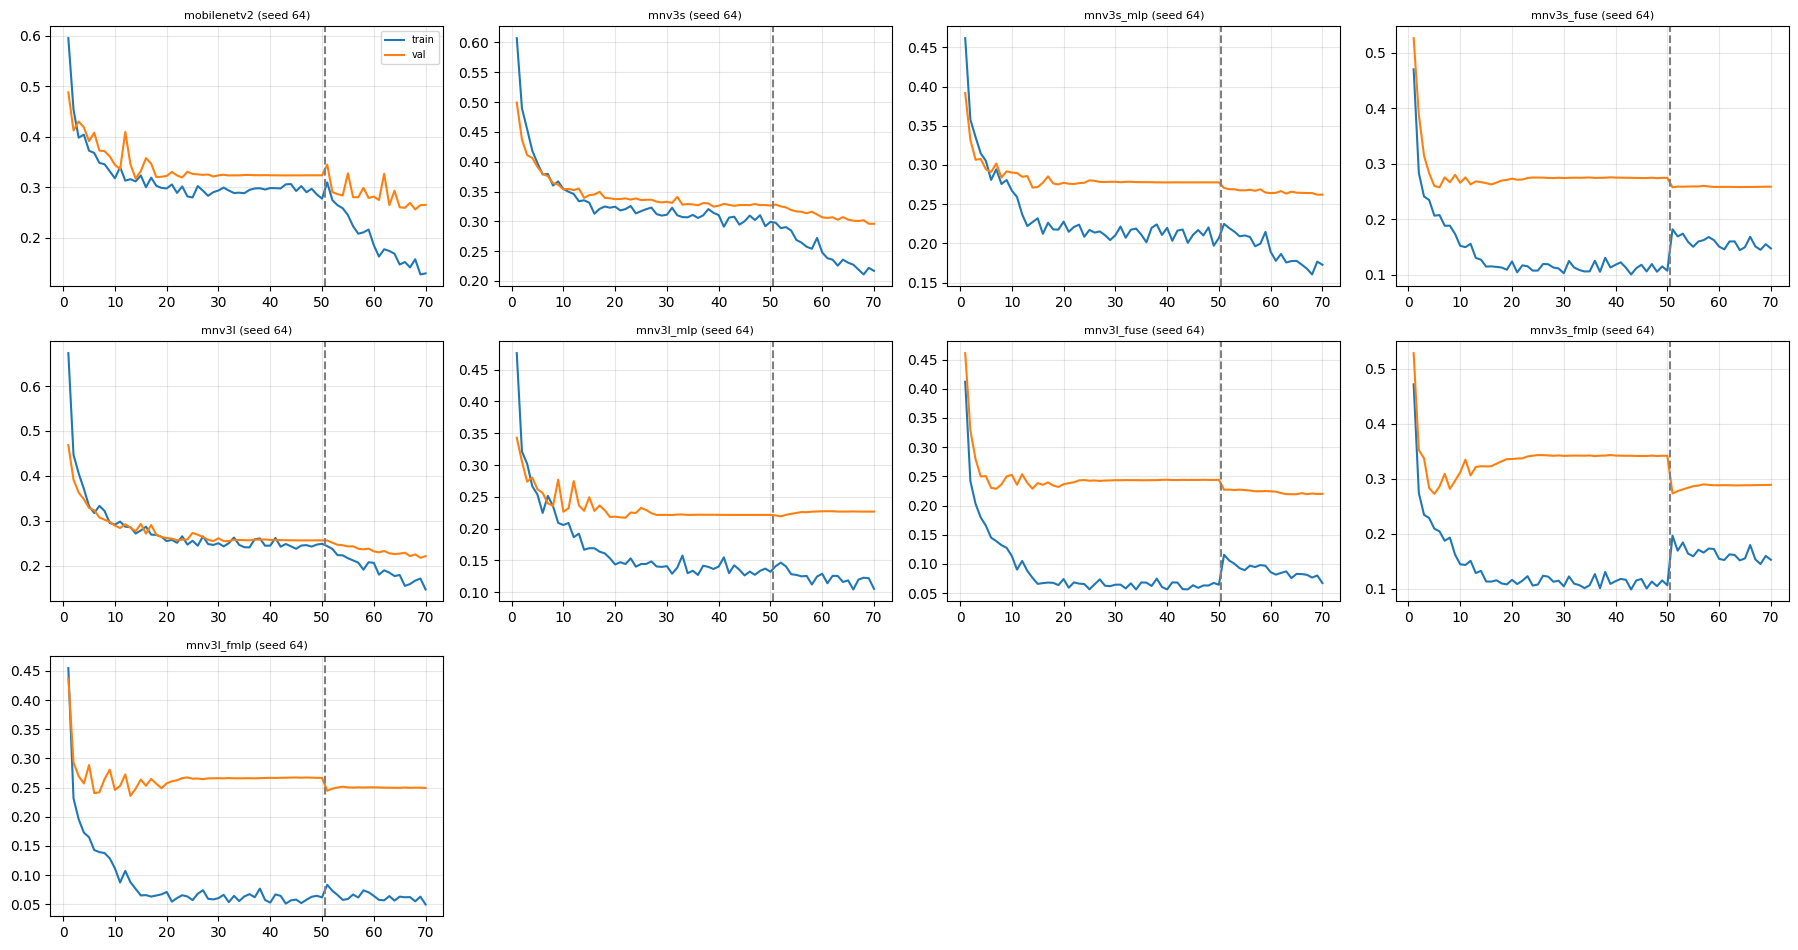

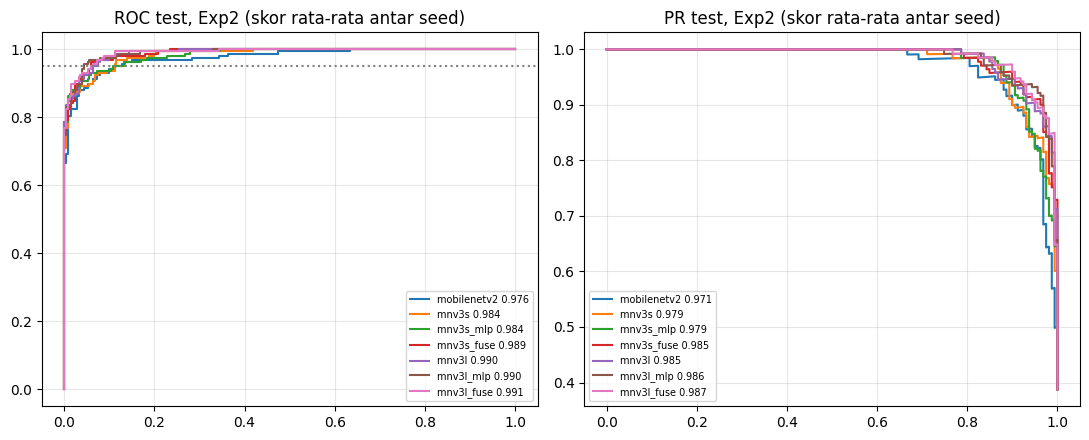

In [ ]:
s0 = common[0]
nc = 4
nr = int(np.ceil(len(models) / nc))
fig, ax = plt.subplots(nr, nc, figsize=(4.5 * nc, 3.2 * nr), squeeze=False)
for a in ax.ravel():
    a.axis("off")
for a, m in zip(ax.ravel(), models):
    a.axis("on")
    e = ep[(ep.model == m) & (ep.seed == s0)].reset_index(drop=True)
    n1 = int((e.exp == "Exp1").sum())
    x = np.arange(1, len(e) + 1)
    a.plot(x, e.loss, label="train")
    a.plot(x, e.val_loss, label="val")
    a.axvline(n1 + 0.5, ls="--", c="gray")
    a.set_title(f"{m} (seed {s0})", fontsize=8)
    a.grid(alpha=0.3)
ax[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/reports/loss_curves.png", dpi=200)
plt.show()

MAIN = [
    m
    for m in (
        "mobilenetv2",
        "mnv3s",
        "mnv3s_mlp",
        "mnv3s_fuse",
        "mnv3l",
        "mnv3l_mlp",
        "mnv3l_fuse",
    )
    if m in models
]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for m in MAIN:
    p, y = seedavg(m, "Exp2")
    fpr, tpr, _ = roc_curve(y, p)
    pc, rc, _ = precision_recall_curve(y, p)
    ax[0].plot(fpr, tpr, label=f"{m} {roc_auc_score(y, p):.3f}")
    ax[1].plot(rc, pc, label=f"{m} {average_precision_score(y, p):.3f}")
ax[0].axhline(0.95, ls=":", c="gray")
ax[0].set_title("ROC test, Exp2 (skor rata-rata antar seed)")
ax[1].set_title("PR test, Exp2 (skor rata-rata antar seed)")
for a in ax:
    a.legend(fontsize=7)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/reports/roc_pr.png", dpi=200)
plt.show()

## 18. Analisis: trade-off akurasi vs biaya

Biaya vs akurasi (Exp2). Rasio terhadap mnv3l. Latensi batch-1 didominasi overhead; throughput lebih informatif.


,params_M,head_params_k,GFLOPs,latency_ms_b1,img_per_s,train_min,roc_auc,roc_auc_sd,far_r95,far_r95_sd,params_M_x_ref,GFLOPs_x_ref,img_per_s_x_ref
model,,,,,,,,,,,,,
mobilenetv2,2.2593,1.281,0.5990,5.2148,709.4330,5.5981,0.9752,0.0027,0.1448,0.0304,0.7538,1.3990,0.8950
mnv3s,0.9397,0.577,0.1098,5.1309,2016.4244,2.9856,0.9840,0.0007,0.1116,0.0040,0.3135,0.2564,2.5438
mnv3s_mlp,0.9761,36.993,0.1099,5.2648,2047.5760,2.9706,0.9833,0.0026,0.1222,0.0283,0.3257,0.2566,2.5831
mnv3s_fuse,0.9846,45.441,0.1164,5.5040,1983.9777,3.2226,0.9870,0.0032,0.0823,0.0283,0.3285,0.2720,2.5029
mnv3l,2.9973,0.961,0.4282,6.1668,792.6685,5.3147,0.9894,0.0008,0.0730,0.0128,1.0000,1.0000,1.0000
mnv3l_mlp,3.0579,61.569,0.4283,6.2010,783.8496,5.1810,0.9888,0.0015,0.0558,0.0080,1.0202,1.0003,0.9889
mnv3l_fuse,3.0705,74.113,0.4388,6.6983,773.6831,5.4194,0.9894,0.0018,0.0677,0.0138,1.0244,1.0249,0.9760
mnv3s_fmlp,0.9887,49.601,0.1164,5.5665,1951.6741,3.2944,0.9870,0.0023,0.0784,0.0302,0.3299,0.2720,2.4622
mnv3l_fmlp,3.0746,78.273,0.4388,6.7659,788.7996,5.4652,0.9882,0.0008,0.0770,0.0083,1.0258,1.0249,0.9951


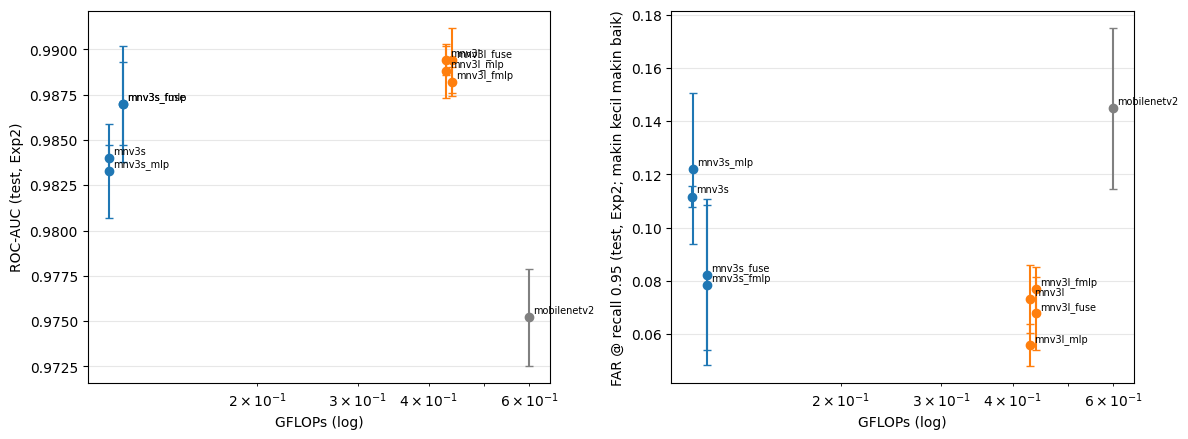

In [ ]:
REF = "mnv3l" if "mnv3l" in models else models[0]
cx = (
    cfg.groupby("model")[
        ["params_total", "params_head", "flops_g", "latency_ms_b1", "throughput_ips"]
    ]
    .mean()
    .loc[models]
)
tot = M.groupby(["model", "seed"]).seconds.sum().groupby("model").mean()
e2 = M[M.exp == "Exp2"].groupby("model")
tab = pd.DataFrame(
    {
        "params_M": cx.params_total / 1e6,
        "head_params_k": cx.params_head / 1e3,
        "GFLOPs": cx.flops_g,
        "latency_ms_b1": cx.latency_ms_b1,
        "img_per_s": cx.throughput_ips,
        "train_min": tot / 60,
        "roc_auc": e2.roc_auc.mean(),
        "roc_auc_sd": e2.roc_auc.std().fillna(0),
        "far_r95": e2.far_r95.mean(),
        "far_r95_sd": e2.far_r95.std().fillna(0),
    }
).loc[models]
for c in ("params_M", "GFLOPs", "img_per_s"):
    tab[c + "_x_ref"] = tab[c] / tab.loc[REF, c]
tab = tab.round(4)
print(
    f"Biaya vs akurasi (Exp2). Rasio terhadap {REF}. Latensi batch-1 didominasi overhead; throughput lebih informatif."
)
display(tab)

col = {"mobilenetv2": "gray", "mnv3s": "tab:blue", "mnv3l": "tab:orange"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, y, lab in zip(
    ax,
    ("roc_auc", "far_r95"),
    ("ROC-AUC (test, Exp2)", "FAR @ recall 0.95 (test, Exp2; makin kecil makin baik)"),
):
    for m, r in tab.iterrows():
        a.errorbar(
            r.GFLOPs,
            r[y],
            yerr=r[y + "_sd"],
            fmt="o",
            c=col[m.split("_")[0]],
            capsize=3,
        )
        a.annotate(
            m, (r.GFLOPs, r[y]), fontsize=7, xytext=(3, 3), textcoords="offset points"
        )
    a.set_xscale("log")
    a.set_xlabel("GFLOPs (log)")
    a.set_ylabel(lab)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/reports/tradeoff.png", dpi=200)
plt.show()

## 18b. Analisis: efek CLAHE

model: ['mnv3s', 'mnv3s_clahe', 'mnv3s_fmlp', 'mnv3s_fmlp_clahe', 'mnv3l', 'mnv3l_clahe', 'mnv3l_fmlp', 'mnv3l_fmlp_clahe']
seed lengkap: [64, 65, 66] (3 seed)

TEST, Exp2: tanpa CLAHE vs dengan CLAHE (mean ± sd antar seed)


,roc_auc,pr_auc,far_r95,acc_05,f1_05,recall_val,far_val
model,,,,,,,
mnv3s,0.984 ± 0.0007,0.9784 ± 0.0006,0.1116 ± 0.004,0.926 ± 0.0028,0.9037 ± 0.0032,0.9811 ± 0.0063,0.178 ± 0.014
mnv3s_clahe,0.9761 ± 0.0001,0.9661 ± 0.0004,0.1169 ± 0.0151,0.9301 ± 0.0051,0.9091 ± 0.0067,0.9811 ± 0.0,0.2762 ± 0.0046
mnv3s_fmlp,0.987 ± 0.0023,0.9811 ± 0.0041,0.0784 ± 0.0302,0.939 ± 0.0146,0.9213 ± 0.0185,0.9853 ± 0.0073,0.166 ± 0.014
mnv3s_fmlp_clahe,0.9771 ± 0.0012,0.9666 ± 0.0018,0.1116 ± 0.0144,0.9301 ± 0.0051,0.9091 ± 0.0066,0.9811 ± 0.0063,0.2297 ± 0.0662
mnv3l,0.9894 ± 0.0008,0.9847 ± 0.001,0.073 ± 0.0128,0.9374 ± 0.0051,0.92 ± 0.0066,0.9811 ± 0.0063,0.1062 ± 0.0115
mnv3l_clahe,0.981 ± 0.0006,0.9758 ± 0.0012,0.1567 ± 0.0061,0.9179 ± 0.0086,0.8967 ± 0.0097,0.9769 ± 0.0096,0.1992 ± 0.0105
mnv3l_fmlp,0.9882 ± 0.0008,0.9834 ± 0.0017,0.077 ± 0.0083,0.9423 ± 0.0061,0.9258 ± 0.008,0.9853 ± 0.0096,0.1315 ± 0.0222
mnv3l_fmlp_clahe,0.9826 ± 0.0024,0.9781 ± 0.0035,0.1116 ± 0.0311,0.9366 ± 0.0098,0.9185 ± 0.0131,0.9706 ± 0.0192,0.1541 ± 0.0348



TEST, Exp1 (backbone frozen)


,roc_auc,pr_auc,far_r95,acc_05,f1_05,recall_val,far_val
model,,,,,,,
mnv3s,0.9761 ± 0.0005,0.9686 ± 0.0008,0.1328 ± 0.0083,0.9171 ± 0.0,0.8935 ± 0.0004,0.9769 ± 0.0036,0.2284 ± 0.0023
mnv3s_clahe,0.9646 ± 0.0009,0.9524 ± 0.0008,0.1926 ± 0.0061,0.9106 ± 0.0078,0.8856 ± 0.0102,0.9727 ± 0.0036,0.3546 ± 0.0416
mnv3s_fmlp,0.9852 ± 0.0015,0.9789 ± 0.0036,0.089 ± 0.0219,0.939 ± 0.0112,0.9208 ± 0.0143,0.9853 ± 0.0036,0.2138 ± 0.0362
mnv3s_fmlp_clahe,0.9751 ± 0.0019,0.9645 ± 0.0016,0.1328 ± 0.0166,0.9285 ± 0.0078,0.9061 ± 0.0118,0.9853 ± 0.0073,0.2776 ± 0.1137
mnv3l,0.9803 ± 0.0011,0.972 ± 0.0013,0.1222 ± 0.0061,0.9244 ± 0.0024,0.9052 ± 0.0028,0.9727 ± 0.0096,0.166 ± 0.0204
mnv3l_clahe,0.9709 ± 0.0001,0.964 ± 0.001,0.2058 ± 0.0265,0.9033 ± 0.0037,0.8789 ± 0.0044,0.9581 ± 0.0073,0.2351 ± 0.0207
mnv3l_fmlp,0.9877 ± 0.0005,0.9827 ± 0.0009,0.0784 ± 0.0061,0.9407 ± 0.0014,0.9234 ± 0.0033,0.9832 ± 0.0073,0.1328 ± 0.028
mnv3l_fmlp_clahe,0.9819 ± 0.0018,0.977 ± 0.0024,0.0996 ± 0.0287,0.9333 ± 0.0051,0.915 ± 0.0078,0.9665 ± 0.0145,0.1487 ± 0.0362



== Δ roc_auc (Exp2, baru − referensi; positif = lebih baik) | wins = jumlah seed yang baru-nya lebih baik


,n_seed,delta_mean,delta_sd,ci_lo,ci_hi,wins,p_t,p_holm
pair,,,,,,,,
mnv3s_clahe vs mnv3s,3,-0.0079,0.0006,-0.0093,-0.0065,0,0.0017,0.0103
mnv3s_fmlp_clahe vs mnv3s_fmlp,3,-0.0099,0.0015,-0.0138,-0.0061,0,0.0079,0.0396
mnv3l_clahe vs mnv3l,3,-0.0083,0.0003,-0.0091,-0.0075,0,0.0005,0.0033
mnv3l_fmlp_clahe vs mnv3l_fmlp,3,-0.0057,0.0017,-0.0098,-0.0015,0,0.0275,0.1099
mnv3s_fmlp_clahe vs mnv3s_clahe,3,0.0010,0.0011,-0.0018,0.0037,2,0.2773,0.5546
mnv3l_fmlp_clahe vs mnv3l_clahe,3,0.0015,0.0029,-0.0058,0.0088,1,0.4618,0.5546
mnv3s_fmlp_clahe vs mnv3l_clahe,3,-0.0040,0.0017,-0.0083,0.0004,0,0.0586,0.1758


... (2 outputs left out)


== Δ pr_auc (Exp2, baru − referensi; positif = lebih baik) | wins = jumlah seed yang baru-nya lebih baik


,n_seed,delta_mean,delta_sd,ci_lo,ci_hi,wins,p_t,p_holm
pair,,,,,,,,
mnv3s_clahe vs mnv3s,3,-0.0123,0.0006,-0.0137,-0.0109,0,0.0007,0.0050
mnv3s_fmlp_clahe vs mnv3s_fmlp,3,-0.0145,0.0025,-0.0207,-0.0084,0,0.0096,0.0478
mnv3l_clahe vs mnv3l,3,-0.0090,0.0004,-0.0100,-0.0079,0,0.0007,0.0050
mnv3l_fmlp_clahe vs mnv3l_fmlp,3,-0.0053,0.0018,-0.0098,-0.0008,0,0.0364,0.1318
mnv3s_fmlp_clahe vs mnv3s_clahe,3,0.0005,0.0013,-0.0028,0.0037,2,0.5881,0.9661
mnv3l_fmlp_clahe vs mnv3l_clahe,3,0.0023,0.0046,-0.0092,0.0137,2,0.4831,0.9661
mnv3s_fmlp_clahe vs mnv3l_clahe,3,-0.0092,0.0030,-0.0166,-0.0018,0,0.0330,0.1318



== Δ acc_05 (Exp2, baru − referensi; positif = lebih baik) | wins = jumlah seed yang baru-nya lebih baik


,n_seed,delta_mean,delta_sd,ci_lo,ci_hi,wins,p_t,p_holm
pair,,,,,,,,
mnv3s_clahe vs mnv3s,3,0.0041,0.0078,-0.0154,0.0235,2,0.4639,1.0000
mnv3s_fmlp_clahe vs mnv3s_fmlp,3,-0.0089,0.0186,-0.0552,0.0373,1,0.4931,1.0000
mnv3l_clahe vs mnv3l,3,-0.0195,0.0084,-0.0405,0.0015,0,0.0572,0.3431
mnv3l_fmlp_clahe vs mnv3l_fmlp,3,-0.0057,0.0078,-0.0252,0.0138,0,0.3356,1.0000
mnv3s_fmlp_clahe vs mnv3s_clahe,3,0.0000,0.0024,-0.0061,0.0061,1,1.0000,1.0000
mnv3l_fmlp_clahe vs mnv3l_clahe,3,0.0187,0.0183,-0.0268,0.0642,2,0.2189,1.0000
mnv3s_fmlp_clahe vs mnv3l_clahe,3,0.0122,0.0042,0.0017,0.0227,3,0.0377,0.2642


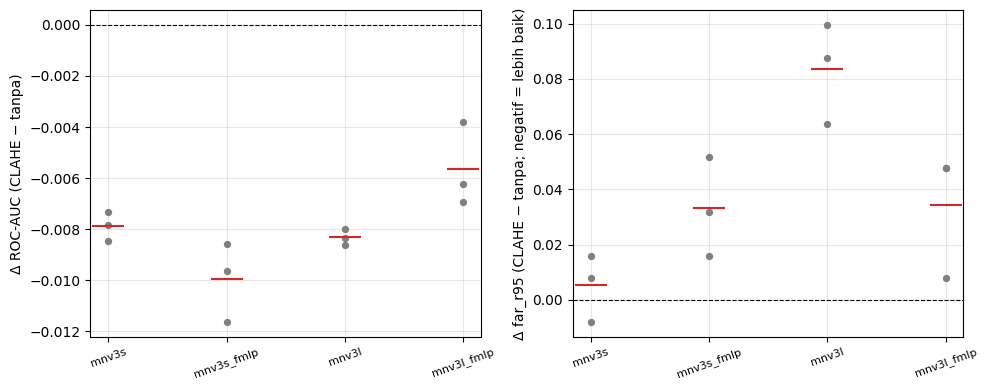

tersimpan di /kaggle/working/runs/reports/ (clahe_*.csv, clahe_effect.png)


In [ ]:
import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score

os.makedirs(f"{OUT_DIR}/reports", exist_ok=True)
try:
    display
except NameError:
    display = print

done_c = [
    d
    for d in sorted(glob.glob(f"{OUT_DIR}/*_img{IMG}_seed*"))
    if os.path.exists(f"{d}/DONE")
]
res_c = pd.concat([pd.read_csv(f"{d}/results.csv") for d in done_c], ignore_index=True)
res_c["thr_type"] = res_c.thr_type.astype(str)
pr_c = pd.concat([pd.read_csv(f"{d}/preds.csv") for d in done_c], ignore_index=True)
have = set(res_c.model)
CL = [m for m in CLAHE_MODELS if m in have and m + "_clahe" in have]
assert CL, (
    "Belum ada pasangan baseline + CLAHE yang selesai (jalankan sel 2b dan sel 14 dulu)."
)
CM = [x for m in CL for x in (m, m + "_clahe")]
cseeds = sorted(set.intersection(*[set(res_c[res_c.model == m].seed) for m in CM]))
assert cseeds, "Tidak ada seed yang lengkap untuk semua pasangan."
print("model:", CM)
print("seed lengkap:", cseeds, f"({len(cseeds)} seed)")


def far_at_recall(y, p, r):
    fpr, tpr, _ = roc_curve(y, p)
    return float(fpr[np.argmax(tpr >= r)])


def holm(p):
    p = np.asarray(p, float)
    adj = np.empty_like(p)
    mx = 0
    for r, i in enumerate(np.argsort(p)):
        mx = max(mx, (len(p) - r) * p[i])
        adj[i] = min(1, mx)
    return adj


rows = []
sel = pr_c[(pr_c.split == "test") & pr_c.model.isin(CM) & pr_c.seed.isin(cseeds)]
for (m, s, e), g in sel.groupby(["model", "seed", "exp"]):
    y, p = g.y_true.values, g.p_fire.values
    rows.append(
        dict(
            model=m,
            seed=s,
            exp=e,
            roc_auc=roc_auc_score(y, p),
            pr_auc=average_precision_score(y, p),
            far_r95=far_at_recall(y, p, 0.95),
        )
    )
MC = pd.DataFrame(rows)
key = ["model", "seed", "exp"]
t = res_c[(res_c.split == "test") & res_c.model.isin(CM) & res_c.seed.isin(cseeds)]
MC = MC.merge(
    t[t.thr_type == "0.5"][key + ["acc", "f1_fire"]].rename(
        columns={"acc": "acc_05", "f1_fire": "f1_05"}
    ),
    on=key,
)
MC = MC.merge(
    t[t.thr_type == "val"][key + ["recall_fire", "far"]].rename(
        columns={"recall_fire": "recall_val", "far": "far_val"}
    ),
    on=key,
)

CC = ["roc_auc", "pr_auc", "far_r95", "acc_05", "f1_05", "recall_val", "far_val"]


def fmt_c(df):
    g = df.groupby("model")[CC]
    mu, sd = g.mean(), g.std(ddof=1).fillna(0)
    return (mu.round(4).astype(str) + " ± " + sd.round(4).astype(str)).loc[CM]


clahe_summary = fmt_c(MC[MC.exp == "Exp2"])
print("\nTEST, Exp2: tanpa CLAHE vs dengan CLAHE (mean ± sd antar seed)")
display(clahe_summary)
print("\nTEST, Exp1 (backbone frozen)")
display(fmt_c(MC[MC.exp == "Exp1"]))

SIGN_C = {"roc_auc": 1, "pr_auc": 1, "far_r95": -1, "acc_05": 1}
PAIRS_C = [(f"{m}_clahe vs {m}", m + "_clahe", m) for m in CL]
for b in ("mnv3s", "mnv3l"):
    if b in CL and b + "_fmlp" in CL:
        PAIRS_C.append(
            (f"{b}_fmlp_clahe vs {b}_clahe", b + "_fmlp_clahe", b + "_clahe")
        )
if "mnv3s_fmlp_clahe" in CM and "mnv3l_clahe" in CM:
    PAIRS_C.append(
        ("mnv3s_fmlp_clahe vs mnv3l_clahe", "mnv3s_fmlp_clahe", "mnv3l_clahe")
    )


def paired_c(exp="Exp2"):
    out = []
    for lab, new, ref in PAIRS_C:
        for met in SIGN_C:
            a = MC[(MC.model == new) & (MC.exp == exp)].set_index("seed")[met]
            b = MC[(MC.model == ref) & (MC.exp == exp)].set_index("seed")[met]
            d = (a - b).dropna()
            n = len(d)
            mu = d.mean()
            sd = d.std(ddof=1) if n > 1 else np.nan
            if n > 1 and sd > 0:
                p = stats.ttest_1samp(d, 0).pvalue
                h = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
            else:
                p, h = (0.0 if (n > 1 and mu != 0) else 1.0), np.nan
            out.append(
                dict(
                    pair=lab,
                    metric=met,
                    n_seed=n,
                    delta_mean=mu,
                    delta_sd=sd,
                    ci_lo=mu - h,
                    ci_hi=mu + h,
                    wins=int((d * SIGN_C[met] > 0).sum()),
                    p_t=p,
                )
            )
    r = pd.DataFrame(out)
    r["p_holm"] = r.groupby("metric").p_t.transform(lambda s: holm(s.values))
    return r


PT_C = paired_c("Exp2")
for met in ("roc_auc", "far_r95", "pr_auc", "acc_05"):
    print(
        f"\n== Δ {met} (Exp2, baru − referensi; {'positif' if SIGN_C[met] > 0 else 'NEGATIF'} = lebih baik) | wins = jumlah seed yang baru-nya lebih baik"
    )
    display(
        PT_C[PT_C.metric == met]
        .set_index("pair")[
            [
                "n_seed",
                "delta_mean",
                "delta_sd",
                "ci_lo",
                "ci_hi",
                "wins",
                "p_t",
                "p_holm",
            ]
        ]
        .round(4)
    )

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, met, lab in zip(
    ax,
    ("roc_auc", "far_r95"),
    ("Δ ROC-AUC (CLAHE − tanpa)", "Δ far_r95 (CLAHE − tanpa; negatif = lebih baik)"),
):
    for i, m in enumerate(CL):
        d = (
            MC[(MC.model == m + "_clahe") & (MC.exp == "Exp2")].set_index("seed")[met]
            - MC[(MC.model == m) & (MC.exp == "Exp2")].set_index("seed")[met]
        ).dropna()
        a.scatter([i] * len(d), d.values, c="gray", s=18, zorder=3)
        a.scatter(i, d.mean(), c="tab:red", marker="_", s=500, zorder=4)
    a.axhline(0, ls="--", c="k", lw=0.8)
    a.set_xticks(range(len(CL)))
    a.set_xticklabels(CL, rotation=20, fontsize=8)
    a.set_ylabel(lab)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/reports/clahe_effect.png", dpi=200)
plt.show()

clahe_summary.to_csv(f"{OUT_DIR}/reports/clahe_summary_exp2_mean_sd.csv")
MC.to_csv(f"{OUT_DIR}/reports/clahe_metrics_per_run.csv", index=False)
PT_C.to_csv(f"{OUT_DIR}/reports/clahe_paired_deltas.csv", index=False)
print("tersimpan di", f"{OUT_DIR}/reports/ (clahe_*.csv, clahe_effect.png)")

## 19. Save

In [ ]:
summary.to_csv(f"{OUT_DIR}/reports/summary_exp2_mean_sd.csv")
M.to_csv(f"{OUT_DIR}/reports/metrics_per_run.csv", index=False)
PT.to_csv(f"{OUT_DIR}/reports/paired_seed_deltas.csv", index=False)
BR.to_csv(f"{OUT_DIR}/reports/bootstrap_seedavg.csv")
ft.to_csv(f"{OUT_DIR}/reports/finetune_effect.csv")
tab.to_csv(f"{OUT_DIR}/reports/tradeoff.csv")
zip_path = shutil.make_archive(
    f"{os.path.dirname(OUT_DIR)}/runs_{len(common)}seeds", "zip", OUT_DIR
)
print(zip_path)
try:
    from google.colab import files

    files.download(zip_path)
except Exception:
    pass

/kaggle/working/runs_3seeds.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 20. Upload hasil ke Kaggle Dataset

In [ ]:
if UPLOAD_RESULTS:
    import os, sys, json, shutil, subprocess, time

    DS_SLUG = "firedet-runs"
    DS_TITLE = "FireDet runs - MobileNetV3 heads (mlp, fuse, fmlp) multi-seed"

    try:
        if ON_KAGGLE:
            from kaggle_secrets import UserSecretsClient

            _s = UserSecretsClient()
            _u, _k = _s.get_secret("KAGGLE_USERNAME"), _s.get_secret("KAGGLE_KEY")
        else:
            from google.colab import userdata

            _u, _k = userdata.get("KAGGLE_USERNAME"), userdata.get("KAGGLE_KEY")
        os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = _u, _k
    except Exception as e:
        raise RuntimeError(
            f"Secrets KAGGLE_USERNAME / KAGGLE_KEY belum diisi ({type(e).__name__})"
        )

    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"])
    zip_file = globals().get("zip_path") or shutil.make_archive(
        f"{os.path.dirname(OUT_DIR)}/runs_{len(SEEDS)}seeds", "zip", OUT_DIR
    )
    UP = f"{os.path.dirname(OUT_DIR)}/kaggle_upload"
    shutil.rmtree(UP, ignore_errors=True)
    os.makedirs(UP)
    shutil.copy(zip_file, UP)
    ds_id = f"{_u}/{DS_SLUG}"
    json.dump(
        {"title": DS_TITLE, "id": ds_id, "licenses": [{"name": "CC0-1.0"}]},
        open(f"{UP}/dataset-metadata.json", "w"),
    )

    def kg(*args):
        r = subprocess.run(["kaggle", *args], capture_output=True, text=True)
        print((r.stdout + r.stderr).strip())
        return r

    exists = ds_id in kg("datasets", "list", "--mine", "-s", DS_SLUG, "--csv").stdout
    if exists:
        print("Dataset sudah ada -> upload sebagai versi baru")
        kg(
            "datasets",
            "version",
            "-p",
            UP,
            "-m",
            f"{len(SEEDS)} seeds + CLAHE | {time.strftime('%Y-%m-%d %H:%M')}",
        )
    else:
        print("Dataset belum ada -> dibuat baru (private)")
        kg("datasets", "create", "-p", UP)
    print("https://www.kaggle.com/datasets/" + ds_id)
else:
    print(
        "UPLOAD_RESULTS = False -> hasil hanya ada di OUT_DIR (sudah dizip di sel 19)."
    )

ref,title,size,lastUpdated,downloadCount,voteCount,usabilityRating
ferdiannurfariza/firedet-runs,firedet-runs,0,2026-10-22 13:01:08.527000,2,0,0.11764706
Dataset sudah ada -> upload sebagai versi baru
Starting upload for file runs_3seeds.zip
Upload successful: runs_3seeds.zip (898MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/ferdiannurfariza/firedet-runs

  0%|          | 0.00/898M [00:00<?, ?B/s]
  1%|          | 9.11M/898M [00:00<00:13, 68.4MB/s]
  3%|▎         | 27.1M/898M [00:00<00:07, 118MB/s] 
  5%|▍         | 40.7M/898M [00:00<00:07, 128MB/s]
  6%|▌         | 53.3M/898M [00:00<00:07, 123MB/s]
  8%|▊         | 68.8M/898M [00:00<00:06, 136MB/s]
  9%|▉         | 82.0M/898M [00:00<00:07, 120MB/s]
 11%|█         | 97.7M/898M [00:00<00:06, 133MB/s]
 12%|█▏        | 111M/898M [00:00<00:06, 131MB/s] 
 14%|█▍        | 126M/898M [00:01<00:06, 134MB/s]
 16%|█▌        | 141M/898M [00:01<00:05, 140MB/s]
 18%|█▊        | 158M/898M [00:01<00:05,